3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]


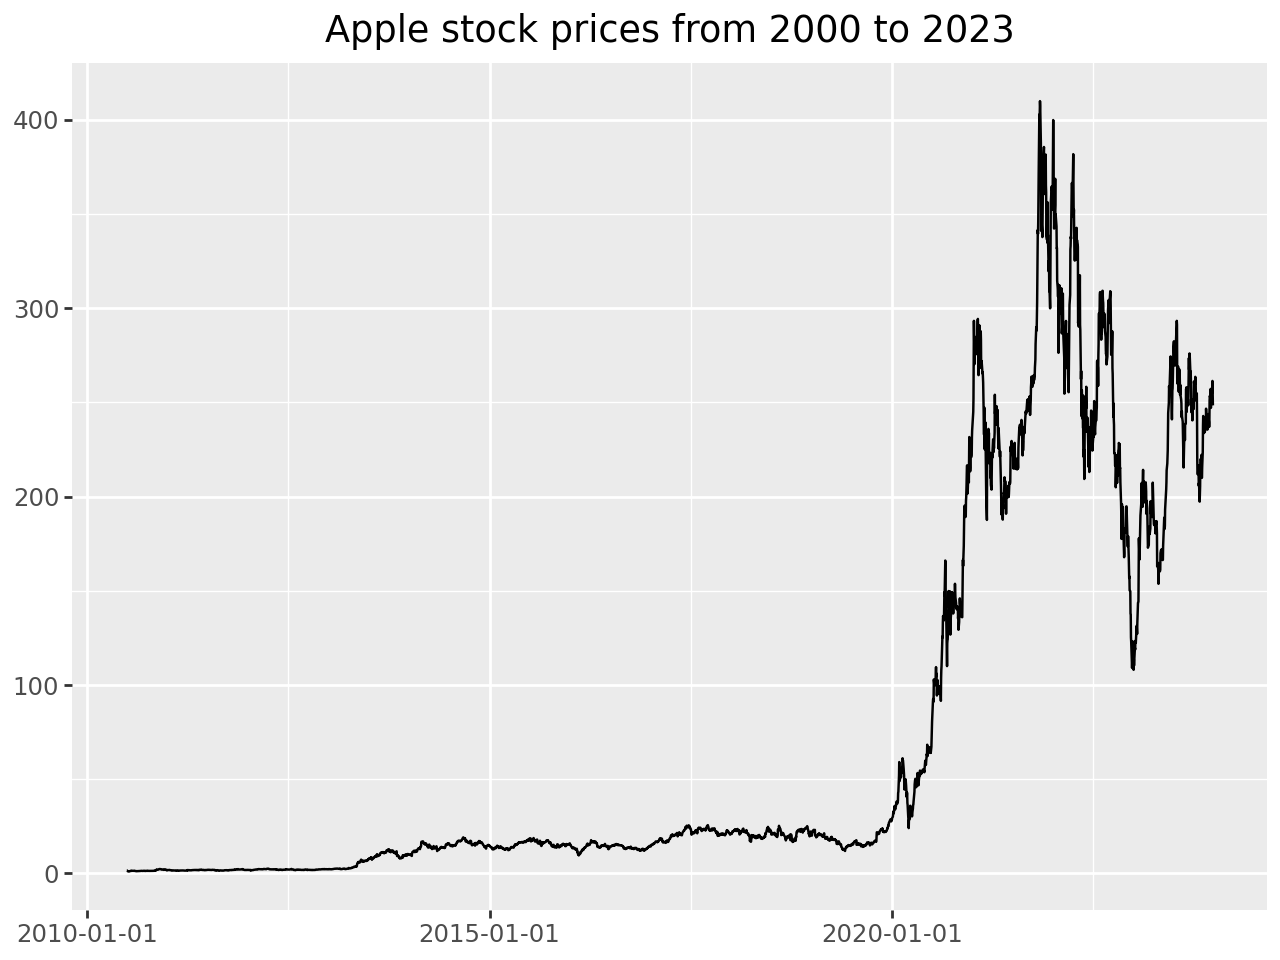

/usr/local/lib/python3.12/dist-packages/plotnine/layer.py:284: PlotnineWarning: stat_bin : Removed 1 rows containing non-finite values.


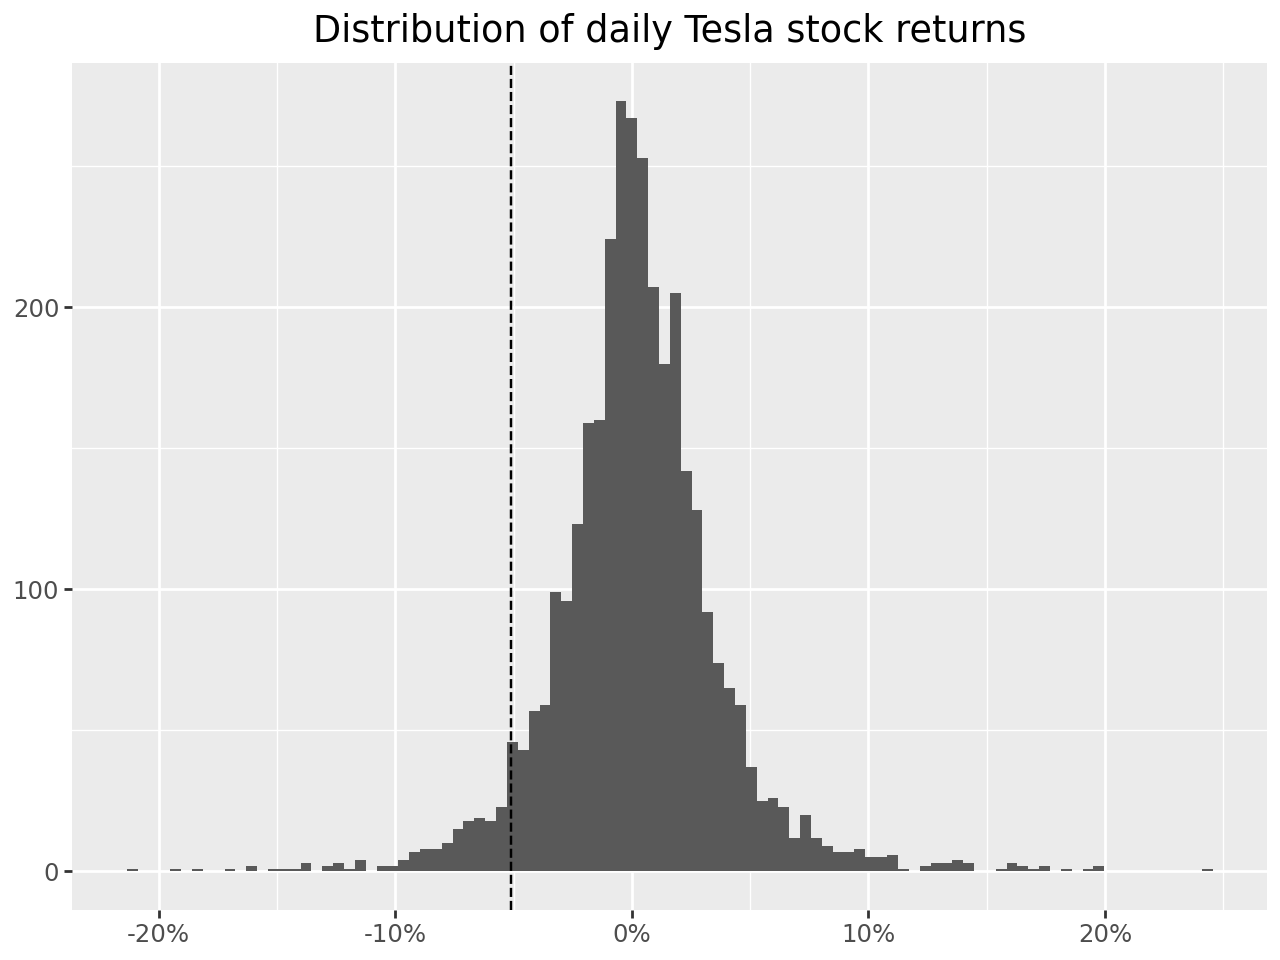

,count,mean,std,min,25%,50%,75%,max
date,,,,,,,,
2010,129.0,0.002,0.046,-0.161,-0.020,0.001,0.027,0.192
2011,252.0,0.001,0.032,-0.097,-0.017,-0.000,0.019,0.170
2012,250.0,0.001,0.034,-0.193,-0.015,0.000,0.019,0.167
2013,252.0,0.007,0.043,-0.145,-0.013,0.005,0.023,0.244
2014,252.0,0.002,0.030,-0.113,-0.015,0.000,0.017,0.157
2015,252.0,0.001,0.024,-0.089,-0.011,0.000,0.012,0.112
2016,252.0,-0.000,0.024,-0.105,-0.014,0.000,0.014,0.087
2017,251.0,0.002,0.022,-0.072,-0.010,0.001,0.016,0.073
2018,251.0,0.001,0.037,-0.139,-0.020,-0.002,0.018,0.173


In [ ]:
#!pip install yfinance pandas-datareader statsmodels seaborn
!pip install -q tidyfinance

import sys
print(sys.version)

### Required packages
#- numpy
#- pandas
#- matplotlib
#- statsmodels
#- yfinance
#- tidyfinance

import pandas as pd
import numpy as np
import tidyfinance as tf

prices = tf.download_data (
    domain = 'stock_prices',
    symbols = 'TSLA',
    start_date = '2000-01-01',
    end_date = '2023-12-31'
)
#downloads stock market data from Yahoo Finance
#adjusted value is what we care about, as it accounts for
#value after splits and dividends end of market day

prices.head().round(3)

from plotnine import *

#the format "import *" here is ok because plotnine has very specific
#functions which arent likely to be polluted

apple_prices_figure = (
    ggplot(prices, aes(y="adjusted_close", x="date"))
    + geom_line()
    + labs(x="", y="", title="Apple stock prices from 2000 to 2023")
)

#creates the chart for displaying data

apple_prices_figure.show()

#shows the figure

returns = (prices
  .sort_values("date")
  .assign(ret=lambda x: x["adjusted_close"].pct_change())
  .get(["symbol", "date", "ret"])
)
returns

#shows daily returns, sorting by date
#defines daily returns as the pct change of the adjusted close
#creates a table with 3 columns: symbol, date, returns

#sort_values() sorts values, obv
#to use descending dates, use ascending = False

#returns = returns.dropna()
# this function will eliminate data values of NA as to not screw up sums and
# values

from mizani.formatters import percent_format

quantile_05 = returns["ret"].quantile(0.05)

#marks the quantile at 0.05, or at the bottom 5% of returns
#useful for monitoring the "worst event" of stock performances
#also connected to Value-at-Risk

apple_returns_figure = (
    ggplot(returns, aes(x="ret"))
    + geom_histogram(bins=100)
    + geom_vline(aes(xintercept=quantile_05), linetype="dashed")
    + labs(x="", y="", title="Distribution of daily Apple stock returns")
    + scale_x_continuous(labels=percent_format())
)
apple_returns_figure.show()

#this creates a histogram of all returns over the timeline of data we pulled
#+ geom_vline created a dotted line at the 0.05 quintile
#VERY IMPORTANT TO KNOW
#bins=100 sets the number of bins to 100, thus implicitly setting the width of of the bins

pd.DataFrame(returns["ret"].describe()).round(3).T

#computes summary statistics for returns
#standard practice to do this for any variables of interest
#the "T" at the end represents total, but we can group by year instead (or other units of time)

#ONLY WORKS FOR A SINGLE STOCK in this current format

(returns["ret"]
  .groupby(returns["date"].dt.year)
  .describe()
  .round(3)
 )


3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]


/usr/local/lib/python3.12/dist-packages/mizani/breaks.py:448: FutureWarning: Passing the width as the parameter has been deprecated and will not work in a future version. Use breaks_date(width="4 years")


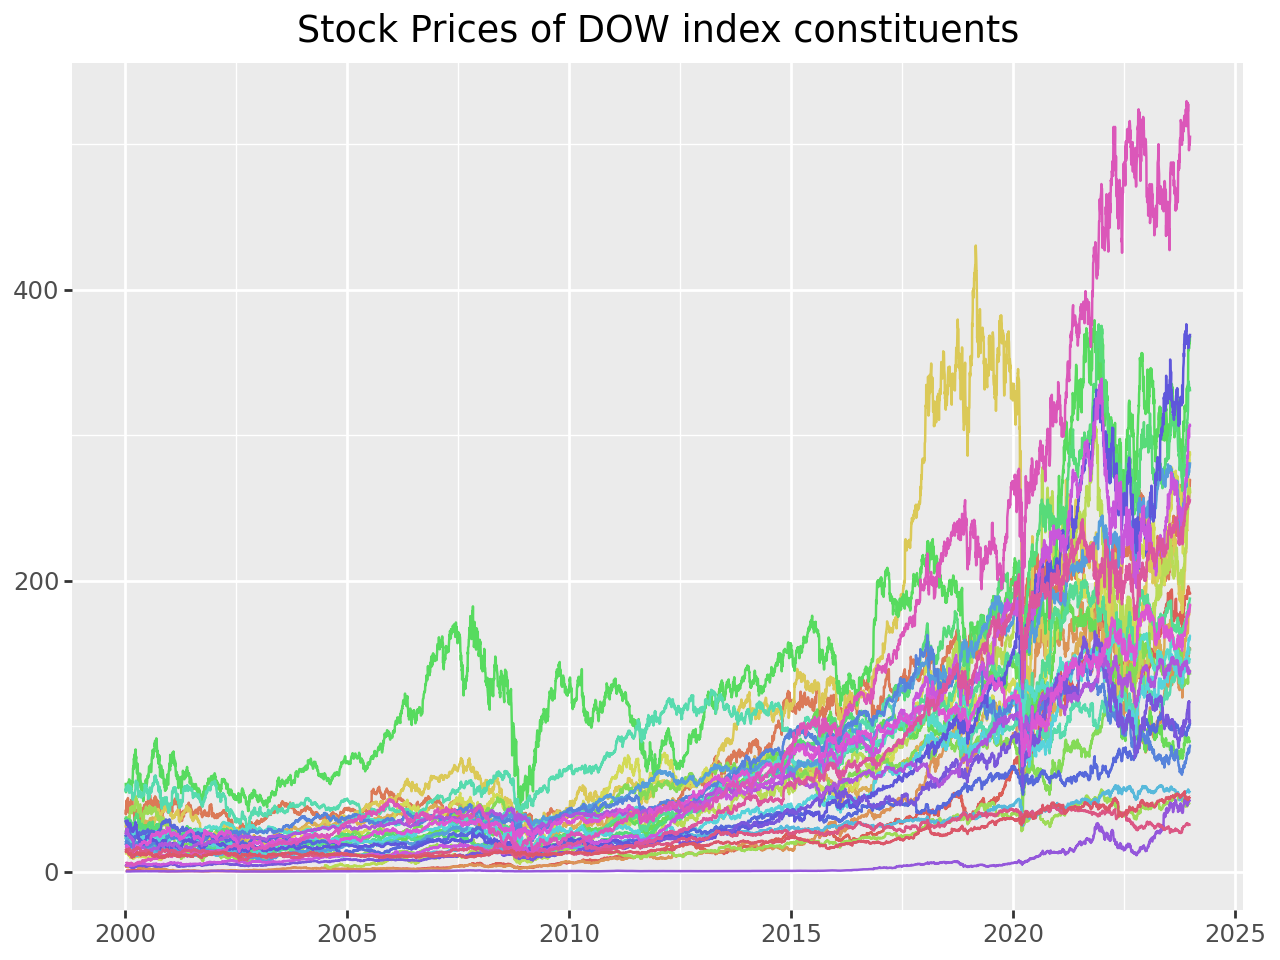

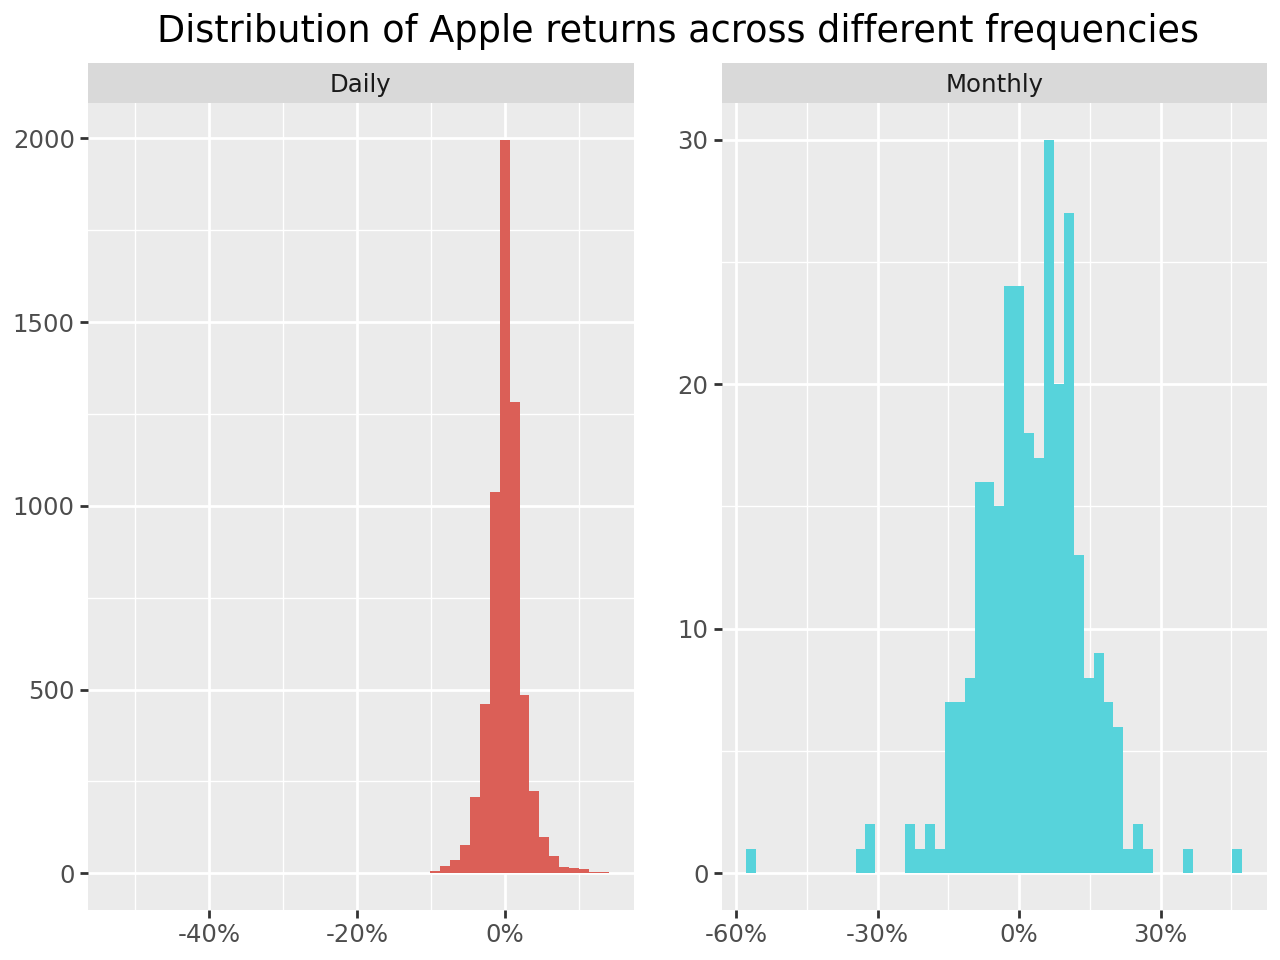

/usr/local/lib/python3.12/dist-packages/mizani/breaks.py:448: FutureWarning: Passing the width as the parameter has been deprecated and will not work in a future version. Use breaks_date(width="4 years")


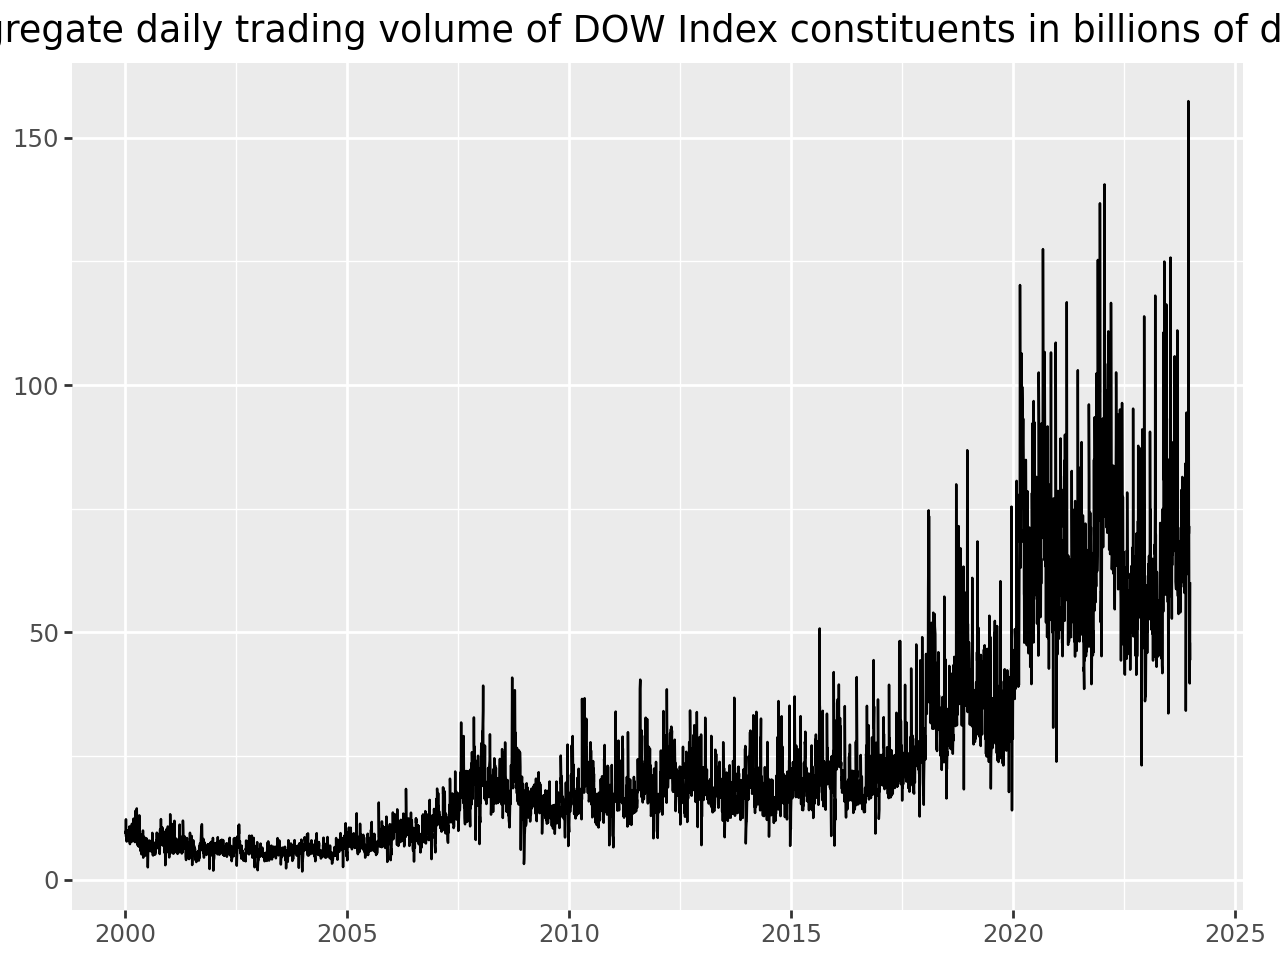

/usr/local/lib/python3.12/dist-packages/plotnine/layer.py:364: PlotnineWarning: geom_point : Removed 1 rows containing missing values.


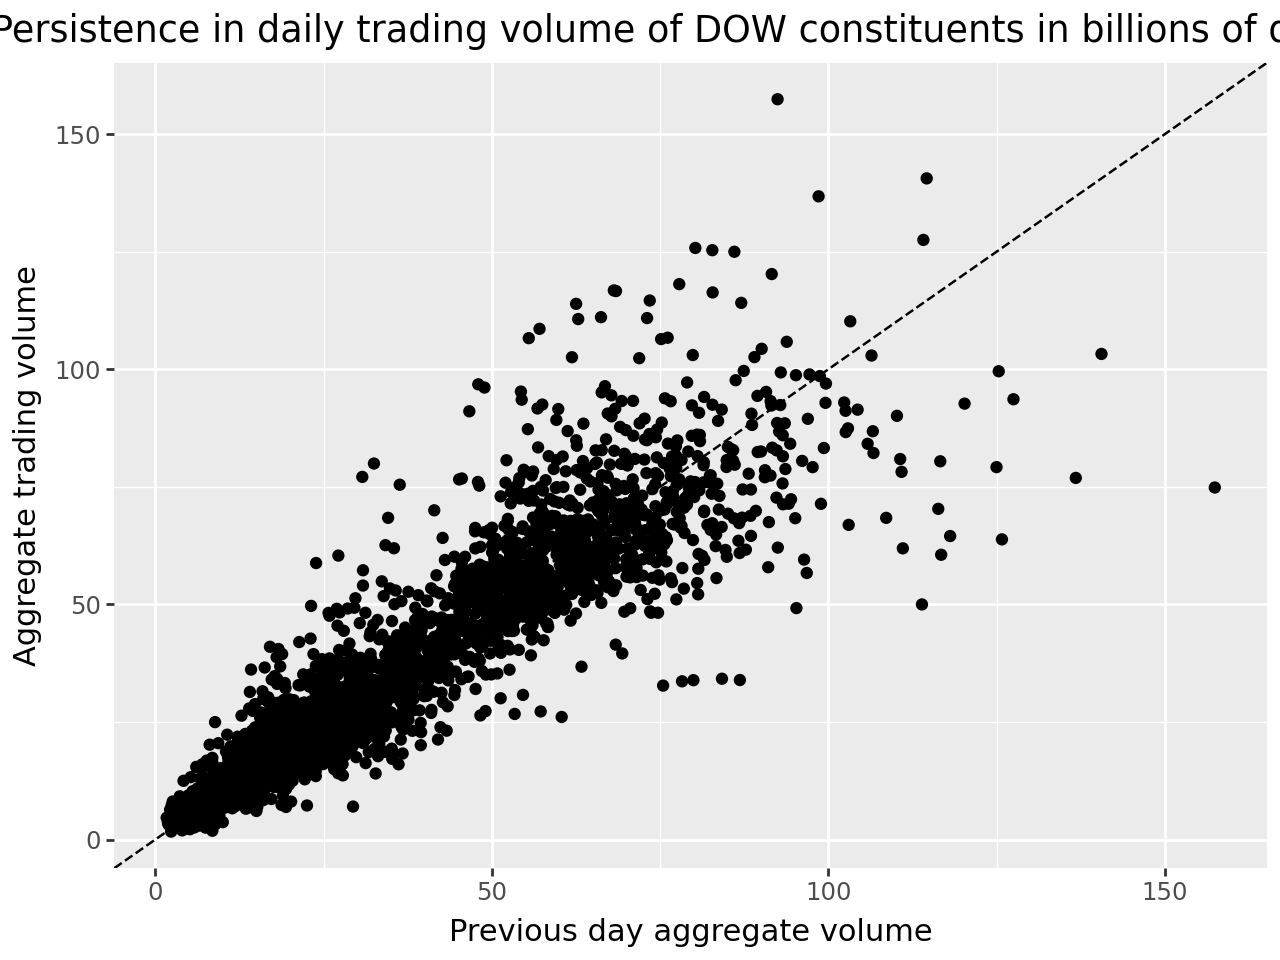

In [ ]:
!pip install -q tidyfinance

import sys
print(sys.version)

import pandas as pd
import numpy as np
import tidyfinance as tf

from plotnine import *

from mizani.formatters import percent_format

#start

#now we generalize the code to computate for any number of stocks
#we can do this by setting symbol = to various stocks we want to analyze
#eg. symbol = ["AAPL", "MMM", "BA"]

#for this, we'll use the Dow Jones Industrial Average index

symbols = tf.download_data(
    domain="constituents",
    index="Dow Jones Industrial Average"
)

#here we use domain "constituents"

# we can also get all stock prices from an index for a specific point in time
# with a single call

prices_daily = tf.download_data(
    domain="stock_prices",
    symbols=symbols["symbol"].tolist(),
    start_date="2000-01-01",
    end_date="2023-12-31"
)

#now we use tf.download_data() with domain="stock_prices" to call prices,
#but we call each stock at once using symbols=symbols["symbol"].tolist()
#this transfers our DataFrame to a column of symbols to a Python list,
#as tf.download_data() expects symbols in a Python list

price_figure = (
    ggplot(prices_daily, aes(y="adjusted_close",x="date",color="symbol"))
    + geom_line()
    + scale_x_datetime(date_breaks="5 years", date_labels="%Y")
    + labs(x="", y="", color="", title="Stock Prices of DOW index constituents")
    + theme(legend_position="none")
)

#here we plot the data, using + theme(legend_position="none") to delete the legend
#we also display dates on the bottom using the + scale_x_datetime(), where
#date_labels=""
#%Y = 4 digit years
#%y = 2 digit years
#"%Y-%m" = year + month
#"%b %Y" = year + month w/ month in text

price_figure.show()

#now we do the same for returns

returns_daily = (prices_daily
    .assign(ret=lambda x: x.groupby("symbol")["adjusted_close"].pct_change())
    .get(["symbol", "date", "ret"])
    .dropna(subset="ret")
)

#.assign creates a new column in the DataFrame prices_daily, where the row value
#is equal to the pct change in the adjusted_close of that stock from the day prior


(returns_daily
 .groupby("symbol")["ret"]
 .describe()
 .round(3)
)

#because financial data often comes in different frequencies (trade data every day, while GDP or other reports are often quarterly)
#we want to be able to convert the data to other periods
#here we will compute our daily returns to a monthly period

returns_monthly = (returns_daily
  .assign(date=returns_daily["date"].dt.to_period("M").dt.to_timestamp())
  .groupby(["symbol", "date"], as_index=False)
  .agg(ret=("ret", lambda x: np.prod(1 + x) - 1))
)

#.assign(colume_name = value) creates a new DataFrame with a new column using an existing DataFrame

apple_daily = (returns_daily
  .query("symbol == 'AAPL'")
  .assign(frequency = "Daily")
)

apple_monthly = (returns_monthly
  .query("symbol == 'AAPL'")
  .assign(frequency = "Monthly")
)

apple_returns = pd.concat([apple_daily, apple_monthly], ignore_index=True)

#now we create a figure to compare daily vs monthly returns

apple_returns_figure = (
    ggplot(apple_returns, aes(x="ret", fill="frequency"))
    + geom_histogram(position="identity", bins=50)
    + labs(
        x="", y="", fill="Frequency",
        title = "Distribution of Apple returns across different frequencies"
    )
    + scale_x_continuous(labels=percent_format())
    + facet_wrap("frequency", scales = "free")
    + theme(legend_position="none")
)
apple_returns_figure.show()

#we can also calculate trading volume in dollars by creating a df with column trading_volume
#we just calculate this as volume (shares) * adjusted_close
#now we group by date, so it graphs the sum volume of all stocks in the index

trading_volume = (prices_daily
    .assign(trading_volume = lambda x: (x["volume"]*x["adjusted_close"]/1e9))
    .groupby("date")["trading_volume"]
    .sum()
    .reset_index()
    .assign(trading_volume_lag = lambda x: x["trading_volume"].shift(periods=1))
)

#we can graph trading volume of the index over the years

trading_volume_figure = (
    ggplot(trading_volume, aes(x="date",y="trading_volume"))
    + geom_line()
    + scale_x_datetime(date_breaks="5 years", date_labels = "%Y")
    + labs(
        x="", y="",
        title = "Aggregate daily trading volume of DOW Index constituents in billions of dollars"
    )
)
trading_volume_figure.show()

#next, we create a scattergraph measuring the persistance of trades

persistence_figure = (
    ggplot(trading_volume, aes(x="trading_volume_lag", y="trading_volume"))
    + geom_point()
    + geom_abline(aes(intercept = 0, slope=1), linetype = "dashed")
    + labs(
        x="Previous day aggregate volume", y="Aggregate trading volume",
        title = "Persistence in daily trading volume of DOW constituents in billions of dollars"
    )
)
persistence_figure.show()

